# BRVM database: a guided tour

This notebook shows how to use **`brvm.db`**, the SQLite database built from the BRVM *Bulletins Officiels de la Cote* (2016-08-01 onwards) by `extract_boc.py`.

Each section answers a typical question with one SQL query and one table or chart:

1. [Setup](#1-setup)
2. [What is in the database](#2-what-is-in-the-database)
3. [Market snapshot on the latest session](#3-market-snapshot-on-the-latest-session)
4. [Splits and adjusted prices](#4-splits-and-adjusted-prices)
5. [One stock in depth: SONATEL](#5-one-stock-in-depth-sonatel)
6. [Comparing stocks](#6-comparing-stocks)
7. [Indices](#7-indices)
8. [Market activity and breadth](#8-market-activity-and-breadth)
9. [Valuation: PER and dividend yield](#9-valuation-per-and-dividend-yield)
10. [Bonds](#10-bonds)
11. [Order book: bid-ask spreads](#11-order-book-bid-ask-spreads)
12. [Mutual funds](#12-mutual-funds)
13. [Corporate events and shareholder meetings](#13-corporate-events-and-shareholder-meetings)
14. [Data quality](#14-data-quality)
15. [Exporting data](#15-exporting-data)

The schema and the meaning of every column are documented in [EXTRACTION.md](EXTRACTION.md).

**Refreshing the data:** run `python download_all.py` then `python extract_boc.py`, and re-run this notebook (*Run All*).

## 1. Setup

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from cycler import cycler

DB = Path("brvm.db")
con = sqlite3.connect(DB)


def sql(query: str, params=(), dates=("date",)) -> pd.DataFrame:
    """Run a query and return a DataFrame, with date columns parsed."""
    df = pd.read_sql(query, con, params=params)
    for c in dates:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c])
    return df


# Chart style: validated categorical palette (fixed order), recessive grid, one axis per chart.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
POS, NEG = "#2a78d6", "#e34948"  # diverging poles: up / down
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.unicode_minus": False, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2,
    "ytick.labelcolor": INK2, "text.color": INK, "legend.frameon": False, "lines.linewidth": 1.6,
    "axes.prop_cycle": cycler(color=SERIES), "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 20


def label_ends(ax, series: dict, fmt="{name}"):
    """Direct labels at the end of each line (used with <= 4 series, in addition to the legend).
    Labels closer than 4 % of the y-range are pushed apart so they never overlap."""
    ends = sorted(((s.dropna().iloc[-1], s.dropna().index[-1], name) for name, s in series.items()
                   if s.dropna().size), key=lambda t: t[0])
    lo, hi = ax.get_ylim()
    gap, placed = (hi - lo) * 0.045, []
    for v, x, name in ends:
        y = max(v, placed[-1] + gap) if placed else v
        placed.append(y)
        ax.text(x + pd.Timedelta(days=15), y, fmt.format(name=name, v=v), va="center", fontsize=9, color=INK2)


def drop_spikes(s: pd.Series, window: int = 11, tol: float = 0.25) -> pd.Series:
    """Remove isolated points more than `tol` away from the centred rolling median
    (typos in the bulletin, e.g. a value printed with a missing digit)."""
    med = s.rolling(window, center=True, min_periods=3).median()
    return s[(s / med - 1).abs() <= tol]


billions = mticker.FuncFormatter(lambda x, _: f"{x / 1e9:,.0f} bn")
trillions = mticker.FuncFormatter(lambda x, _: f"{x / 1e12:,.1f} tn")
LAST = pd.Timestamp(con.execute("SELECT MAX(date) FROM documents").fetchone()[0])
print(f"Database: {DB.resolve()}  ({DB.stat().st_size / 1e6:,.0f} MB) - last bulletin: {LAST:%A %d %B %Y}")

Database: C:\Users\isaac.konan\Documents\BRVM\brvm.db  (205 MB) - last bulletin: Tuesday 17 November 2026


## 2. What is in the database

Every table has a `date` column (the trading session of the bulletin). Below: row counts, and the date range covered.

In [2]:
tables = ["documents", "equity_quotes", "bond_quotes", "right_quotes", "order_book", "index_values",
          "market_stats", "fund_navs", "corporate_notices", "general_meetings", "table_totals", "securities"]
pd.DataFrame({t: [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]] for t in tables},
             index=["rows"]).T.style.format("{:,}")

,rows
documents,"2,525"
equity_quotes,"115,248"
bond_quotes,"251,739"
right_quotes,179
order_book,"363,839"
index_values,"27,154"
market_stats,"91,269"
fund_navs,"224,924"
corporate_notices,"12,402"
general_meetings,514


In [3]:
cov = sql("""
    SELECT substr(date, 1, 4) AS year, COUNT(*) AS bulletins, SUM(status = 'ok') AS fully_extracted,
           MIN(date) AS first, MAX(date) AS last
    FROM documents GROUP BY 1 ORDER BY 1""", dates=())
cov

,year,bulletins,fully_extracted,first,last
0,2016,74,74,2016-08-01,2016-12-30
1,2017,247,246,2017-01-02,2017-12-29
2,2018,243,243,2018-01-02,2018-12-31
3,2019,247,247,2019-01-02,2019-12-31
4,2020,251,251,2020-01-02,2020-12-31
5,2021,250,250,2021-01-04,2021-12-31
6,2022,250,250,2022-01-03,2022-12-30
7,2023,247,247,2023-01-02,2023-12-29
8,2024,249,249,2024-01-02,2024-12-31
9,2025,249,249,2025-01-02,2025-12-31


The **`securities`** table is the master list (latest name, sector, compartment and, for bonds, issuer and terms). Listed companies by country and compartment:

In [4]:
eq = sql("""SELECT s.symbol, s.name, s.country, s.compartment, s.sector, s.first_date, s.last_date
            FROM securities s WHERE asset_type = 'equity'""", dates=("first_date", "last_date"))
listed = eq[eq["last_date"] == LAST]
print(f"{len(listed)} equities quoted on the last session, {len(eq)} ever quoted since 2016")
pd.crosstab(listed["country"], listed["compartment"], margins=True, margins_name="Total")

48 equities quoted on the last session, 51 ever quoted since 2016


compartment,PRESTIGE,PRINCIPAL,Total
country,,,
BF,1,1,2
BJ,0,3,3
CI,8,23,31
ML,0,1,1
NE,0,1,1
SN,2,1,3
TG,0,2,2
Total,11,32,43


## 3. Market snapshot on the latest session

The headline indices and market figures come from `index_values` and `market_stats` (a key/value table).

In [5]:
idx = sql("""SELECT index_name, value, change_pct, ytd_pct FROM index_values
             WHERE family = 'headline' AND date = ?""", (LAST.date().isoformat(),))
stats = sql("SELECT key, value FROM market_stats WHERE date = ?", (LAST.date().isoformat(),)).set_index("key")["value"]
print(f"Session of {LAST:%d/%m/%Y}")
for _, r in idx.iterrows():
    print(f"  {r.index_name:<16} {r.value:>9,.2f}   day {r.change_pct:+.2f} %   year-to-date {r.ytd_pct:+.2f} %")
print(f"  Equity market cap   {stats['equity_market_cap'] / 1e12:,.2f} tn FCFA   |  bond market cap {stats['bond_market_cap'] / 1e12:,.2f} tn FCFA")
print(f"  Equities traded     {stats['equity_value'] / 1e6:,.0f} m FCFA ({stats['equity_volume']:,.0f} shares)")
# a count of 0 is printed as a blank cell in the bulletin, hence .get(..., 0)
nb = {k: stats.get(f"equity_nb_{k}", 0) for k in ("up", "down", "unchanged")}
print(f"  Breadth             {nb['up']:.0f} up / {nb['down']:.0f} down / {nb['unchanged']:.0f} unchanged")

Session of 17/11/2026
  BRVM 30             243.13   day -1.93 %   year-to-date +46.25 %
  BRVM COMPOSITE      502.68   day -1.98 %   year-to-date +45.39 %
  BRVM PRESTIGE       188.19   day -1.41 %   year-to-date +30.46 %
  Equity market cap   19.71 tn FCFA   |  bond market cap 13.45 tn FCFA
  Equities traded     2,369 m FCFA (1,134,837 shares)
  Breadth             0 up / 39 down / 7 unchanged


In [6]:
day = sql("""SELECT symbol, name, close, ref_price, change_pct, volume, value, per, net_yield
             FROM equity_quotes WHERE date = ?""", (LAST.date().isoformat(),))
cols = ["symbol", "name", "ref_price", "change_pct", "value"]
gainers = day[day["change_pct"] > 0].nlargest(5, "change_pct")[cols]
losers = day[day["change_pct"] < 0].nsmallest(5, "change_pct")[cols]
print(f"Top gainers ({(day['change_pct'] > 0).sum()} stocks rose):")
display(gainers if len(gainers) else "none - no stock rose in this session")
print(f"Top losers ({(day['change_pct'] < 0).sum()} stocks fell):")
display(losers)

Top gainers (0 stocks rose):


'none - no stock rose in this session'

Top losers (39 stocks fell):


,symbol,name,ref_price,change_pct,value
9,BOAN,BANK OF AFRICA NG,"4,490.00",-7.42,"57,890,875.00"
30,SDSC,AFRICA GLOBAL LOGISTICS CI,"2,580.00",-7.19,"47,766,770.00"
37,SLBC,SOLIBRA CI,"39,495.00",-6.61,"12,563,370.00"
10,BOAS,BANK OF AFRICA SENEGAL,"7,800.00",-6.59,"100,278,580.00"
38,SMBC,SMB CI,"16,450.00",-6.56,"18,471,110.00"


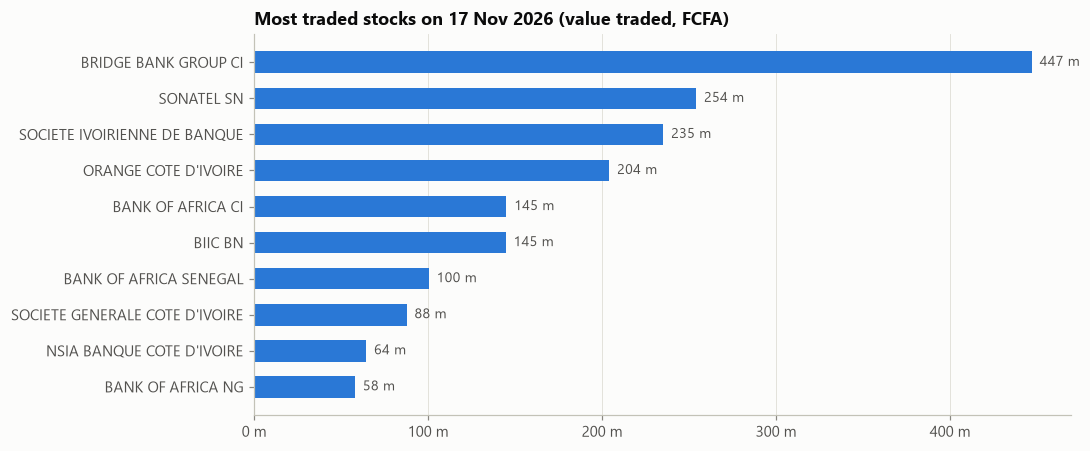

In [7]:
most = day.nlargest(10, "value").sort_values("value")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(most["name"], most["value"], color=SERIES[0], height=0.6)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1e6:,.0f} m"))
ax.grid(axis="y", visible=False)
for y, v in enumerate(most["value"]):
    ax.text(v, y, f"  {v / 1e6:,.0f} m", va="center", fontsize=9, color=INK2)
ax.set_title(f"Most traded stocks on {LAST:%d %b %Y} (value traded, FCFA)")
plt.tight_layout()

## 4. Splits and adjusted prices

Prices in the bulletin are **not adjusted** for splits. BRVM limits daily moves to ±7.5 %, so a reference price that jumps by more than 40 % from one session to the next can only be a corporate action (split or reverse split). The ratio of the two reference prices is the adjustment factor.

Around a split the bulletin is sometimes inconsistent for a few days. For example, after the SEMC 1:40 split in December 2018, `prev_close` still shows the old price. The detector therefore uses `ref_price` only.

In [8]:
px = sql("SELECT date, symbol, ref_price FROM equity_quotes WHERE ref_price > 0 ORDER BY symbol, date")
px["prev_ref"] = px.groupby("symbol")["ref_price"].shift()
px["ratio"] = px["ref_price"] / px["prev_ref"]
is_split = (px["ratio"] < 0.6) | (px["ratio"] > 1.6)
splits = px[is_split].assign(split=lambda d: d["ratio"].map(lambda r: f"1:{1 / r:.0f}" if r < 1 else f"{r:.0f}:1"))
print(f"{len(splits)} corporate actions detected")
splits[["date", "symbol", "prev_ref", "ref_price", "ratio", "split"]].sort_values("date")

58 corporate actions detected


,date,symbol,prev_ref,ref_price,ratio,split
14,2016-10-03,ABJC,"150,000.00","7,105.00",0.05,1:21
73698,2016-11-04,SHEC,"130,995.00","2,700.00",0.02,1:49
8182,2017-06-20,BOAB,"214,495.00","105,000.00",0.49,1:2
13225,2017-06-21,BOAC,"171,990.00","88,385.00",0.51,1:2
10706,2017-06-27,BOABF,"200,000.00","100,000.00",0.50,1:2
20794,2017-06-27,BOAS,"73,950.00","35,500.00",0.48,1:2
94030,2017-07-21,SPHC,"14,350.00","3,000.00",0.21,1:5
5684,2017-07-27,BNBC,"104,000.00","5,500.00",0.05,1:19
66309,2017-07-31,SDSC,"188,000.00","3,970.00",0.02,1:47
41107,2017-08-10,NEIC,"1,100.00",44.00,0.04,1:25


      date  prev_ref  ref_price split
2026-10-23 42,000.00   4,385.00  1:10


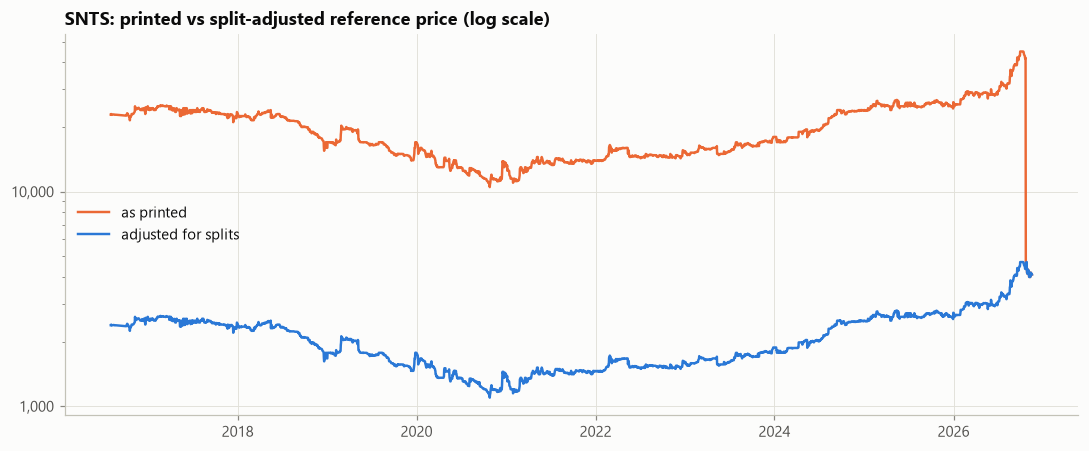

In [9]:
def adjusted_prices(symbols, start=None) -> pd.DataFrame:
    """Reference price series adjusted for splits (pivoted: one column per symbol)."""
    out = {}
    for sym, d in px[px["symbol"].isin(symbols)].groupby("symbol"):
        d = d.set_index("date")
        r = d["ratio"].where((d["ratio"] < 0.6) | (d["ratio"] > 1.6), 1.0).fillna(1.0)
        factor = r[::-1].cumprod()[::-1].shift(-1).fillna(1.0)  # applies to sessions before each split
        out[sym] = d["ref_price"] * factor
    df = pd.DataFrame(out)
    return df[df.index >= pd.Timestamp(start)] if start else df


sym = "SNTS"  # SONATEL split its shares in 2026
print(splits[splits["symbol"] == sym][["date", "prev_ref", "ref_price", "split"]].to_string(index=False))
raw = px[px["symbol"] == sym].set_index("date")["ref_price"]
adj = adjusted_prices([sym])[sym]
fig, ax = plt.subplots()
ax.plot(raw.index, raw, color=SERIES[1], label="as printed")
ax.plot(adj.index, adj, color=SERIES[0], label="adjusted for splits")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="center left")
ax.set_title(f"{sym}: printed vs split-adjusted reference price (log scale)")
plt.tight_layout()

## 5. One stock in depth: SONATEL

`equity_quotes` holds one row per stock and session. `close` is empty when the stock did not trade (see `status_flag = 'NC'`). `ref_price` is always filled, so it is the column to use for a continuous price series. Here it is adjusted for the 2026 split with the helper from section 4.

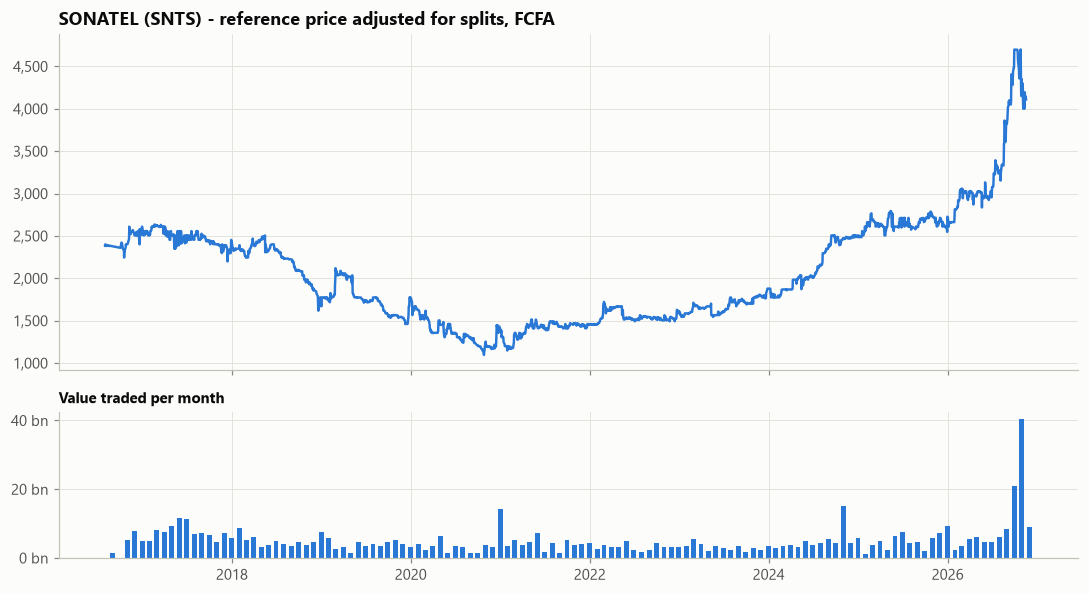

In [10]:
snts = sql("SELECT date, ref_price, close, volume, value, per, net_yield FROM equity_quotes WHERE symbol = 'SNTS' ORDER BY date").set_index("date")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
snts_adj = adjusted_prices(["SNTS"])["SNTS"]
a1.plot(snts_adj.index, snts_adj, color=SERIES[0])
a1.set_title("SONATEL (SNTS) - reference price adjusted for splits, FCFA")
a1.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
monthly = snts["value"].resample("ME").sum()
a2.bar(monthly.index, monthly.values, width=20, color=SERIES[0])
a2.yaxis.set_major_formatter(billions)
a2.set_title("Value traded per month", fontsize=10)
plt.tight_layout()

The *last dividend* columns change when a new dividend is paid, so the dividend history is one `GROUP BY` away. The amounts are as paid, before the 2026 split.

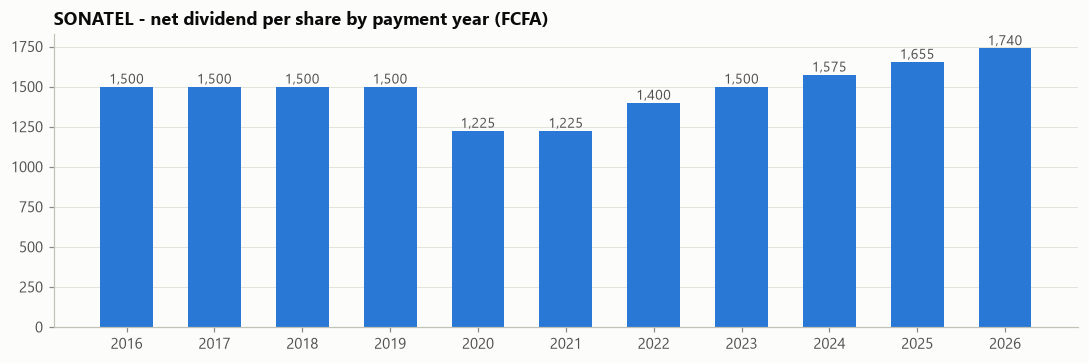

In [11]:
div = sql("""SELECT div_date, MAX(div_amount) AS net_dividend FROM equity_quotes
             WHERE symbol = 'SNTS' AND div_date IS NOT NULL GROUP BY div_date ORDER BY div_date""", dates=("div_date",))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(div["div_date"].dt.year.astype(str), div["net_dividend"], color=SERIES[0], width=0.6)
for x, v in zip(div["div_date"].dt.year.astype(str), div["net_dividend"]):
    ax.text(x, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.grid(axis="x", visible=False)
ax.set_title("SONATEL - net dividend per share by payment year (FCFA)")
plt.tight_layout()

## 6. Comparing stocks

Total price performance of the four most traded stocks, rebased to 100 on the first session of 2021. This uses split-adjusted prices; dividends are not reinvested.

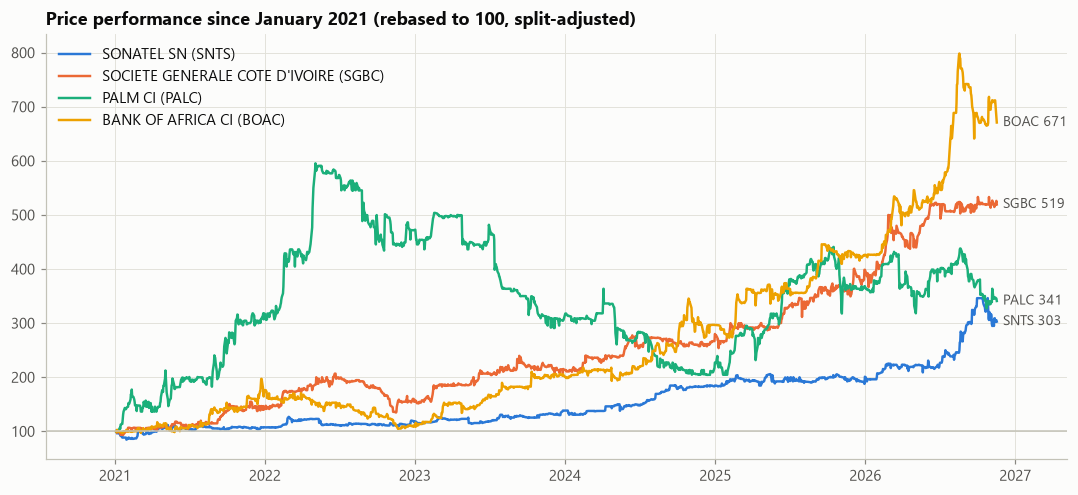

In [12]:
syms = (sql("""SELECT symbol, SUM(value) v FROM equity_quotes WHERE date >= '2021-01-01'
               GROUP BY symbol ORDER BY v DESC LIMIT 4""")["symbol"].tolist())
names = dict(sql("SELECT symbol, name FROM securities").values)
p = adjusted_prices(syms, start="2021-01-01").ffill()
rebased = p / p.bfill().iloc[0] * 100
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, s in enumerate(syms):
    ax.plot(rebased.index, rebased[s], color=SERIES[i], label=f"{names[s]} ({s})")
ax.axhline(100, color=AXIS, linewidth=1)
label_ends(ax, {s: rebased[s] for s in syms}, fmt="{name} {v:,.0f}")
ax.legend(loc="upper left")
ax.set_title("Price performance since January 2021 (rebased to 100, split-adjusted)")
ax.margins(x=0.08)
plt.tight_layout()

In [13]:
# Correlation of daily returns (on sessions where both traded)
rets = adjusted_prices(syms, start="2021-01-01").pct_change(fill_method=None)
rets.rename(columns=names).corr().round(2)

,BANK OF AFRICA CI,PALM CI,SOCIETE GENERALE COTE D'IVOIRE,SONATEL SN
BANK OF AFRICA CI,1.00,0.06,0.06,-0.01
PALM CI,0.06,1.00,0.01,0.02
SOCIETE GENERALE COTE D'IVOIRE,0.06,0.01,1.00,0.04
SONATEL SN,-0.01,0.02,0.04,1.00


## 7. Indices

`index_values` holds the **headline** indices (BRVM Composite since 2016, BRVM 10 until 2022, BRVM 30 / Prestige since 2023), the **compartment** indices and the **sector** indices:
* `family = 'sector'`: the old classification, 2016-2025;
* `family = 'sector_new'`: the new classification, from 2025.

Calendar-year performance (%): 2017: -16.8, 2018: -29.1, 2019: -7.5, 2020: -8.7, 2021: +39.1, 2022: +0.5, 2023: +5.4, 2024: +28.9, 2025: +25.3, 2026: +45.4


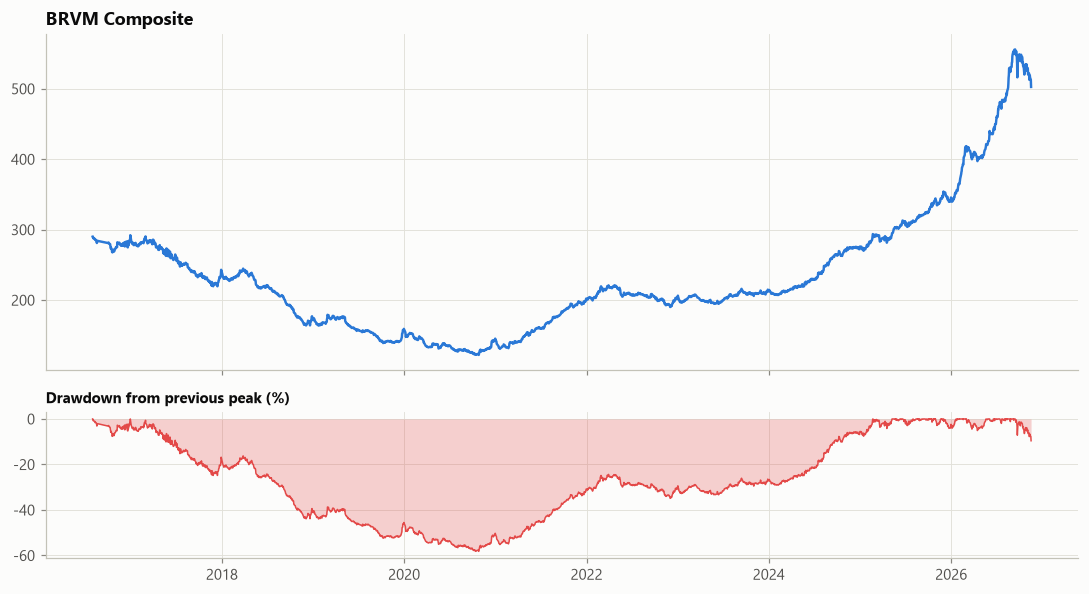

In [14]:
comp = sql("""SELECT date, value FROM index_values WHERE family = 'headline' AND index_name = 'BRVM COMPOSITE'
              ORDER BY date""").set_index("date")["value"]
dd = comp / comp.cummax() - 1
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
a1.plot(comp.index, comp, color=SERIES[0])
a1.set_title("BRVM Composite")
a2.fill_between(dd.index, dd * 100, 0, color=NEG, alpha=0.25, linewidth=0)
a2.plot(dd.index, dd * 100, color=NEG, linewidth=1)
a2.set_title("Drawdown from previous peak (%)", fontsize=10)
plt.tight_layout()
yearly = comp.resample("YE").last().pct_change() * 100
print("Calendar-year performance (%):", ", ".join(f"{d.year}: {v:+.1f}" for d, v in yearly.dropna().items()))

,sector,value,ytd_pct,nb_companies,avg_per
5,Services Publics,207.43,95.87,2,19.05
4,Services Financiers,230.52,58.04,17,15.10
3,Industriels,195.12,47.45,6,125.07
6,Telecommunications,138.08,45.50,3,12.88
2,Energie,159.33,43.66,4,17.75
0,Consommation De Base,253.59,17.36,9,12.37
1,Consommation Discretionnaire,165.39,-4.41,7,37.28


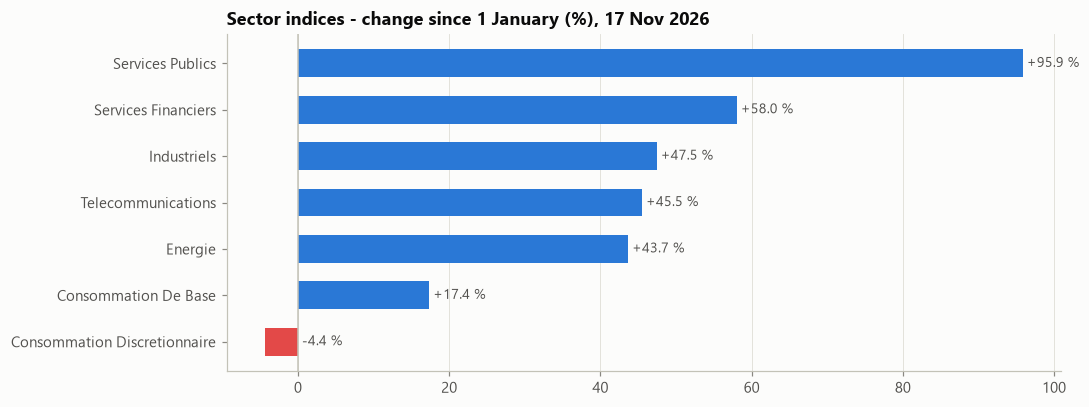

In [15]:
sec = sql("""SELECT index_name, value, ytd_pct, nb_companies, avg_per FROM index_values
             WHERE family = 'sector_new' AND date = ?""", (LAST.date().isoformat(),))
sec = sec.assign(sector=sec["index_name"].str.replace("BRVM ", "").str.title()).sort_values("ytd_pct")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(sec["sector"], sec["ytd_pct"], color=[POS if v >= 0 else NEG for v in sec["ytd_pct"]], height=0.6)
ax.axvline(0, color=AXIS, linewidth=1)
for y, v in enumerate(sec["ytd_pct"]):
    ax.text(max(v, 0), y, f" {v:+.1f} %", va="center", ha="left", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False)
ax.set_title(f"Sector indices - change since 1 January (%), {LAST:%d %b %Y}")
plt.tight_layout()
sec[["sector", "value", "ytd_pct", "nb_companies", "avg_per"]].sort_values("ytd_pct", ascending=False)

## 8. Market activity and breadth

Market figures are in the key/value table `market_stats`. The keys are listed in EXTRACTION.md, e.g. `equity_market_cap`, `bond_market_cap`, `equity_value`, `equity_nb_up`.

points removed: 2 (bonds) 0 (equities)


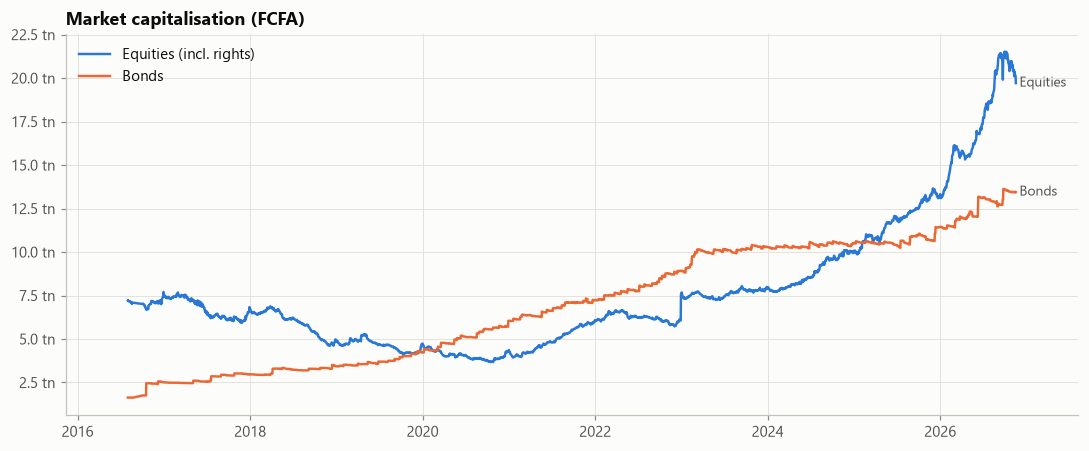

In [16]:
ms = sql("""SELECT date, key, value FROM market_stats
            WHERE key IN ('equity_market_cap', 'bond_market_cap', 'equity_value', 'equity_nb_up', 'equity_nb_down')""")
ms = ms.pivot(index="date", columns="key", values="value")
# Two bulletins print a malformed bond capitalisation (2024-11-11: '10,503,545,90,495'; 2025-01-16: billions
# instead of trillions). The database keeps what is printed; drop_spikes() removes such outliers for charting.
cap_eq, cap_bd = drop_spikes(ms["equity_market_cap"].dropna()), drop_spikes(ms["bond_market_cap"].dropna())
print("points removed:", len(ms["bond_market_cap"].dropna()) - len(cap_bd), "(bonds)",
      len(ms["equity_market_cap"].dropna()) - len(cap_eq), "(equities)")
fig, ax = plt.subplots()
ax.plot(cap_eq.index, cap_eq, color=SERIES[0], label="Equities (incl. rights)")
ax.plot(cap_bd.index, cap_bd, color=SERIES[1], label="Bonds")
ax.yaxis.set_major_formatter(trillions)
label_ends(ax, {"Equities": cap_eq, "Bonds": cap_bd})
ax.legend(loc="upper left")
ax.margins(x=0.07)
ax.set_title("Market capitalisation (FCFA)")
plt.tight_layout()

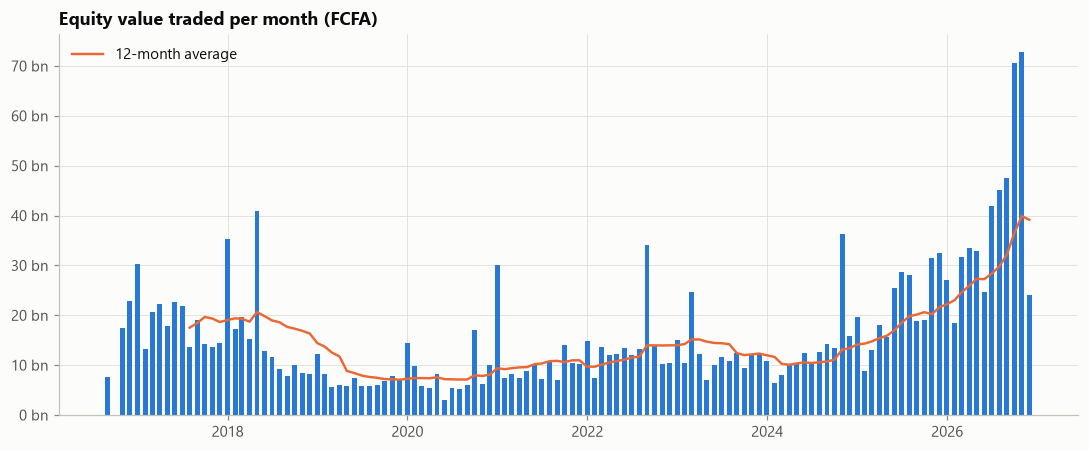

In [17]:
monthly_value = sql("SELECT date, SUM(value) AS v FROM equity_quotes GROUP BY date").set_index("date")["v"].resample("ME").sum()
fig, ax = plt.subplots()
ax.bar(monthly_value.index, monthly_value.values, width=20, color=SERIES[0])
ax.plot(monthly_value.rolling(12).mean(), color=SERIES[1], label="12-month average")
ax.yaxis.set_major_formatter(billions)
ax.legend(loc="upper left")
ax.set_title("Equity value traded per month (FCFA)")
plt.tight_layout()

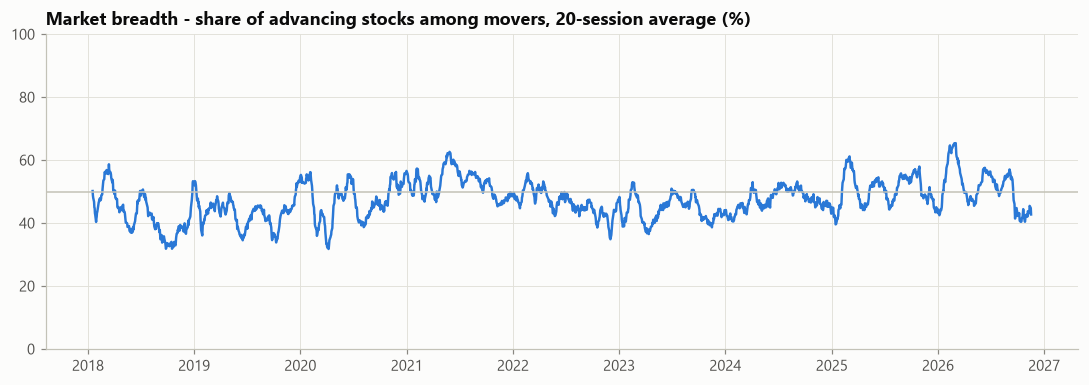

In [18]:
up, down = ms["equity_nb_up"].fillna(0), ms["equity_nb_down"].fillna(0)  # blank = 0 in the bulletin
breadth = (up / (up + down)).dropna() * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(breadth.rolling(20).mean(), color=SERIES[0])
ax.axhline(50, color=AXIS, linewidth=1)
ax.set_ylim(0, 100)
ax.set_title("Market breadth - share of advancing stocks among movers, 20-session average (%)")
plt.tight_layout()

## 9. Valuation: PER and dividend yield

The bulletin prints a PER and a net dividend yield for each stock. Below are the latest values, with the stocks labelled by symbol.

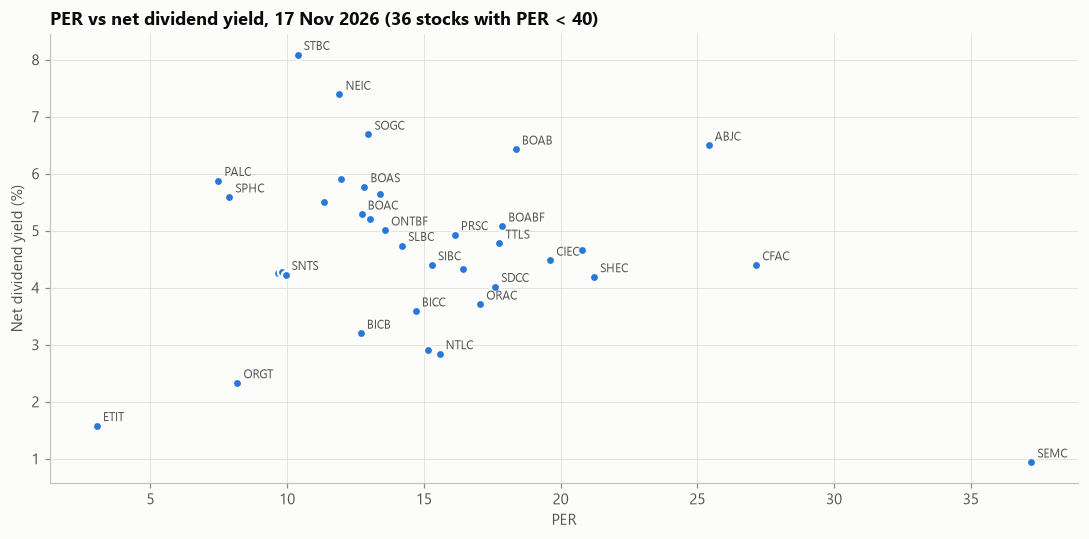

In [19]:
val = day.dropna(subset=["per", "net_yield"])
val = val[(val["per"] > 0) & (val["per"] < 40)]
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(val["per"], val["net_yield"], s=36, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
# label the most traded stocks first, skipping any label that would collide with one already placed
placed = []
for _, r in val.sort_values("value", ascending=False).iterrows():
    if all(abs(r["per"] - x) > 1.4 or abs(r["net_yield"] - y) > 0.22 for x, y in placed):
        ax.annotate(r["symbol"], (r["per"], r["net_yield"]), xytext=(4, 3), textcoords="offset points",
                    fontsize=8, color=INK2)
        placed.append((r["per"], r["net_yield"]))
ax.set_xlabel("PER")
ax.set_ylabel("Net dividend yield (%)")
ax.set_title(f"PER vs net dividend yield, {LAST:%d %b %Y} ({len(val)} stocks with PER < 40)")
plt.tight_layout()

In [20]:
# Market-wide averages over time (printed by the BOC)
mv = sql("SELECT date, key, value FROM market_stats WHERE key IN ('market_per', 'market_yield')").pivot(
    index="date", columns="key", values="value")
mv.resample("YE").mean().rename(columns={"market_per": "average PER", "market_yield": "average yield %"}).set_index(
    mv.resample("YE").mean().index.year)

key,average PER,average yield %
date,,
2017,16.90,5.74
2018,14.36,7.63
2019,10.13,9.09
2020,9.63,10.24
2021,11.30,7.18
2022,9.77,6.49
2023,9.12,8.03
2024,9.67,8.48
2025,14.21,7.70


## 10. Bonds

`bond_quotes` holds every listed bond with its outstanding nominal, price, accrued coupon and next coupon. Issuer, coupon rate and maturity are parsed from the bond name.

In [21]:
b = sql("""SELECT symbol, name, section, issuer, coupon_rate, issue_year, maturity_year, nominal, ref_price,
                  accrued_coupon, periodicity, next_coupon_date, amort_type
           FROM bond_quotes WHERE date = ?""", (LAST.date().isoformat(),))
print(f"{len(b)} bonds listed on {LAST:%d %b %Y}")
b.groupby("issuer").agg(bonds=("symbol", "count"), avg_coupon=("coupon_rate", "mean"),
                        last_maturity=("maturity_year", "max")).sort_values("bonds", ascending=False).head(10)

211 bonds listed on 17 Nov 2026


,bonds,avg_coupon,last_maturity
issuer,,,
TPCI,70,5.86,"2,042.00"
ETAT DU SENEGAL,30,6.54,"2,036.00"
ETAT DU MALI,21,6.27,"2,036.00"
TPBF,10,6.46,"2,034.00"
ETAT DU BURKINA,9,6.54,"2,035.00"
TPBJ,8,5.96,"2,042.00"
TRESOR PUBLIC DU NIGER,7,6.50,"2,034.00"
FCTC EPT,6,7.62,"2,040.00"
CRRH-UEMOA,5,5.98,"2,037.00"


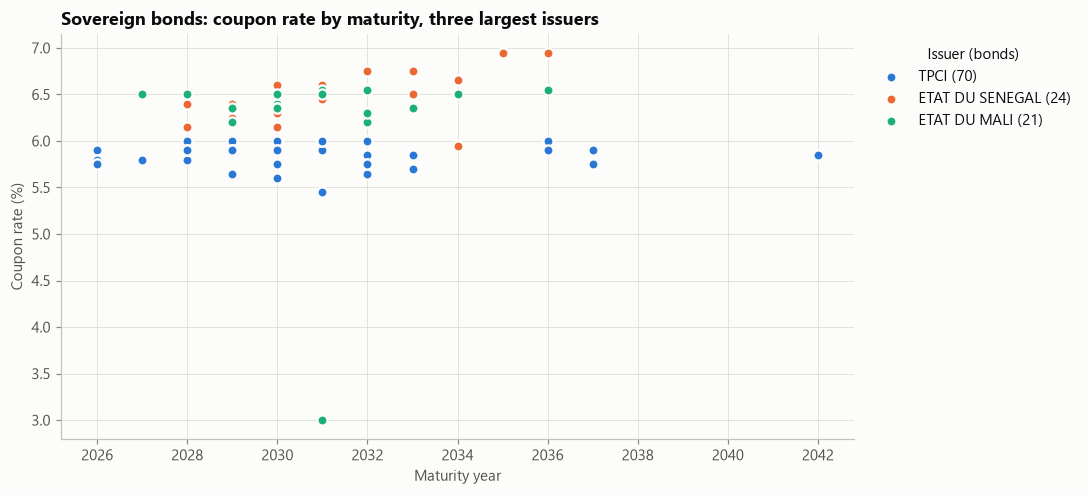

In [22]:
issuers = ["TPCI", "ETAT DU SENEGAL", "ETAT DU MALI"]  # 3 series: the first three palette slots
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, iss in enumerate(issuers):
    d = b[(b["issuer"] == iss) & b["coupon_rate"].notna() & b["maturity_year"].notna()]
    ax.scatter(d["maturity_year"], d["coupon_rate"], s=44, color=SERIES[i], edgecolor=SURFACE, linewidth=1.5,
               label=f"{iss} ({len(d)})", zorder=3)
ax.set_xlabel("Maturity year")
ax.set_ylabel("Coupon rate (%)")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), title="Issuer (bonds)")
ax.set_title("Sovereign bonds: coupon rate by maturity, three largest issuers")
plt.tight_layout()

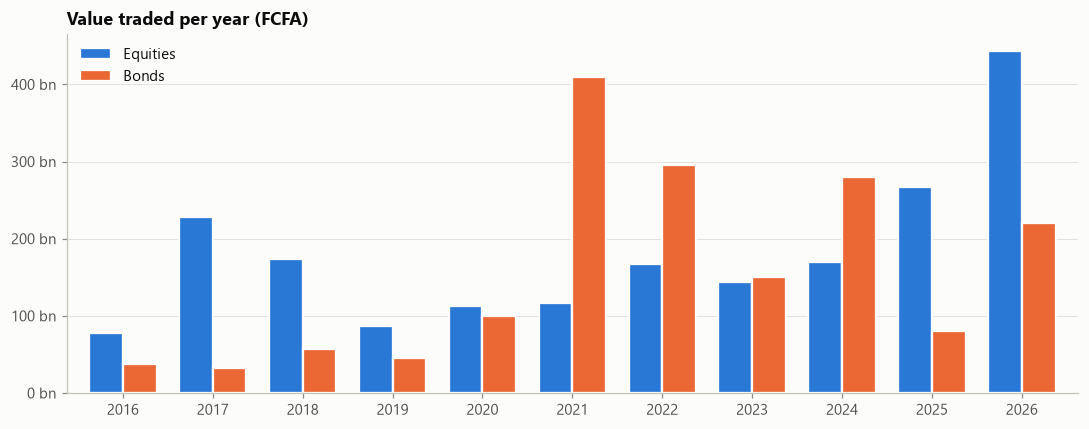

In [23]:
# Value traded per year: equities vs bonds (two series, one axis)
tv = sql("""SELECT substr(date, 1, 4) AS year, 'Equities' AS market, SUM(value) AS v FROM equity_quotes GROUP BY 1
            UNION ALL
            SELECT substr(date, 1, 4), 'Bonds', SUM(value) FROM bond_quotes GROUP BY 1""", dates=())
tv = tv.pivot(index="year", columns="market", values="v")[["Equities", "Bonds"]]
ax = tv.plot.bar(color=SERIES[:2], width=0.75, figsize=(10, 4), edgecolor=SURFACE, linewidth=1.5, rot=0)
ax.legend(title=None, loc="upper left")
ax.yaxis.set_major_formatter(billions)
ax.grid(axis="x", visible=False)
ax.set_xlabel("")
ax.set_title("Value traded per year (FCFA)")
plt.tight_layout()

## 11. Order book: bid-ask spreads

`order_book` records the best bid and ask left at the close. A relative spread, (ask - bid) / mid, measured over the last 60 sessions, gives a simple liquidity ranking.

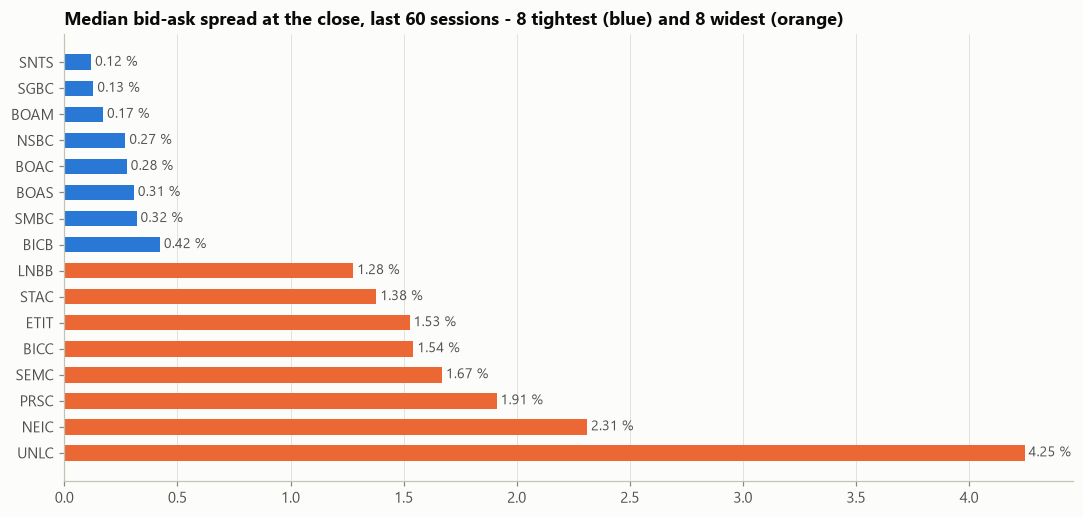

In [24]:
ob = sql("""SELECT date, symbol, bid_price, ask_price FROM order_book
            WHERE market = 'equities' AND bid_price > 0 AND ask_price > 0
              AND date IN (SELECT DISTINCT date FROM order_book ORDER BY date DESC LIMIT 60)""")
ob["spread_pct"] = (ob["ask_price"] - ob["bid_price"]) / ((ob["ask_price"] + ob["bid_price"]) / 2) * 100
spread = ob[ob["spread_pct"] >= 0].groupby("symbol")["spread_pct"].median().sort_values()
show = pd.concat([spread.head(8), spread.tail(8)])
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(show.index, show.values, color=[SERIES[0]] * 8 + [SERIES[1]] * 8, height=0.6)
ax.invert_yaxis()
for y, v in enumerate(show.values):
    ax.text(v, y, f" {v:.2f} %", va="center", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False)
ax.set_title("Median bid-ask spread at the close, last 60 sessions - 8 tightest (blue) and 8 widest (orange)")
plt.tight_layout()

## 12. Mutual funds

`fund_navs` lists the net asset value (VL) of every FCP/SICAV in each bulletin. NAVs are often published with a delay, so the **`nav_date`** column, not the bulletin date, is the valuation date.

In [25]:
cat_names = {"A": "Equity", "D": "Diversified", "OMLT": "Medium/long-term bond", "OCT": "Short-term bond",
             "OATC": "Short-term bond (OATC)", "M": "Money market", "C": "Contractual"}
f_last = sql("SELECT fund_name, manager, category, nav, nav_date, frequency FROM fund_navs WHERE date = ?",
             (LAST.date().isoformat(),), dates=("nav_date",))
f_last.assign(category=f_last["category"].map(cat_names).fillna(f_last["category"])).groupby("category").agg(
    funds=("fund_name", "count"), managers=("manager", "nunique")).sort_values("funds", ascending=False)

,funds,managers
category,,
Diversified,58,21
Medium/long-term bond,35,17
Equity,17,13
Short-term bond,7,7
O,7,2
Money market,5,4
Short-term bond (OATC),2,1
ACTION,1,1
OPCR,1,1


In [26]:
nav = sql("""SELECT DISTINCT fund_name, category, nav_date, nav FROM fund_navs WHERE nav IS NOT NULL""",
          dates=("nav_date",)).dropna(subset=["nav_date"]).drop_duplicates(["fund_name", "nav_date"]).sort_values("nav_date")
last = nav.groupby("fund_name").tail(1)
last = last[last["nav_date"] >= LAST - pd.Timedelta(days=30)]  # funds with a recent NAV
year_ago = last.assign(target=last["nav_date"] - pd.Timedelta(days=365))[["fund_name", "target", "nav", "category"]]
past = pd.merge_asof(year_ago.sort_values("target"), nav.rename(columns={"nav_date": "target", "nav": "nav_1y"})
                     [["fund_name", "target", "nav_1y"]], on="target", by="fund_name", tolerance=pd.Timedelta(days=10))
past["perf_1y_pct"] = (past["nav"] / past["nav_1y"] - 1) * 100
ranking = past.dropna(subset=["perf_1y_pct"]).assign(category=lambda d: d["category"].map(cat_names).fillna(d["category"]))
print(f"1-year NAV performance available for {len(ranking)} funds")
ranking.sort_values("perf_1y_pct", ascending=False)[["fund_name", "category", "nav", "perf_1y_pct"]].head(10)

1-year NAV performance available for 37 funds


,fund_name,category,nav,perf_1y_pct
92,AURORE OPPORTUNITES,Equity,"13,193.18",45.48
41,FCP AAM EPARGNE ACTION,Equity,"13,190.04",43.45
55,FCP SOAGA EPARGNE ACTIONS,Equity,"16,383.04",40.79
49,FCP SOAGA EPARGNE DYNAMIQUE,Equity,"10,355.23",38.14
54,FCP PAM Actions,Equity,"31,733.00",37.52
29,FCP NYESIGUI,Diversified,"20,949.86",36.65
82,NSIA ASSURANCES OPTIMUM,Diversified,"1,640,404.58",25.25
60,EVOLUTIS,Diversified,"8,023.14",24.83
44,FCP PAM Diversifié Equilibré,Diversified,"24,880.00",24.22
36,FCP AAM EPARGNE CROISSANCE,Diversified,"13,730.31",22.34


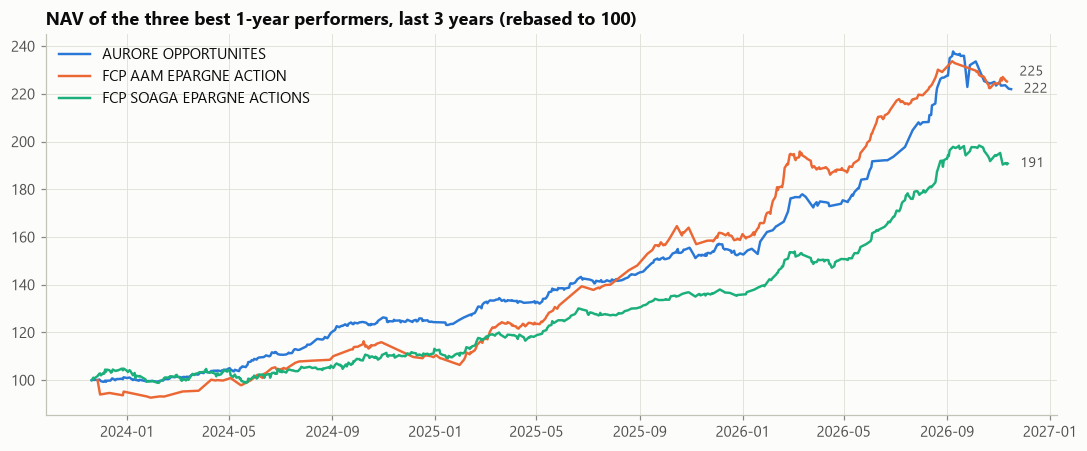

In [27]:
funds = ranking.sort_values("perf_1y_pct", ascending=False)["fund_name"].head(3).tolist()
fig, ax = plt.subplots()
series = {}
for i, f in enumerate(funds):
    s = nav[(nav["fund_name"] == f) & (nav["nav_date"] >= LAST - pd.Timedelta(days=3 * 365))].set_index("nav_date")["nav"]
    s = drop_spikes(s)  # a few NAVs are misprinted in the bulletin
    s = s / s.iloc[0] * 100
    series[f] = s
    ax.plot(s.index, s, color=SERIES[i], label=f)
label_ends(ax, series, fmt="{v:,.0f}")
ax.legend(loc="upper left")
ax.set_title("NAV of the three best 1-year performers, last 3 years (rebased to 100)")
plt.tight_layout()

## 13. Corporate events and shareholder meetings

`corporate_notices` holds the three notice blocks of each bulletin:
* `operation`: operations in progress;
* `avis`: BRVM notices, such as dividend payments;
* `communique`: company releases, such as results and activity reports.

`general_meetings` lists the shareholder meetings, deduplicated across bulletins.

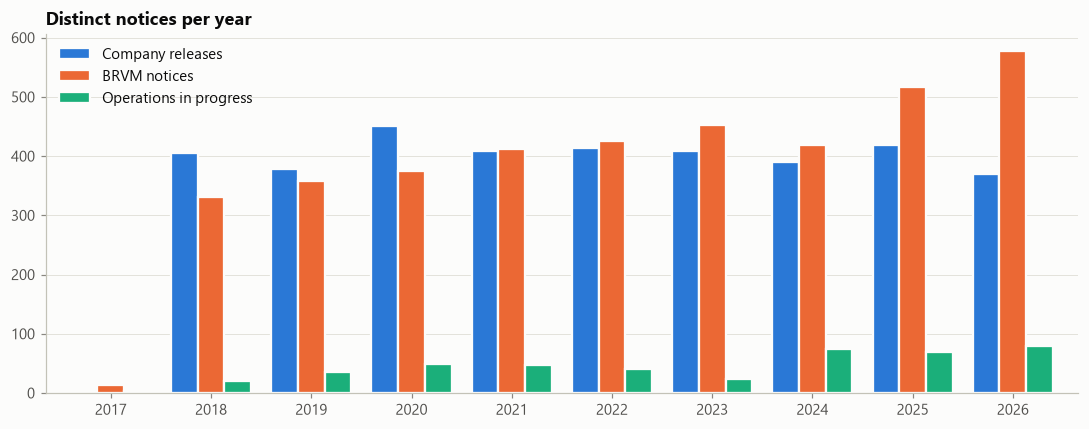

In [28]:
# 'operations in progress' are repeated in every bulletin until they end: count distinct notices
n = sql("""SELECT year, kind, COUNT(*) AS n FROM (
               SELECT DISTINCT substr(date, 1, 4) AS year, kind, company, COALESCE(reference, ''), nature, subject
               FROM corporate_notices) GROUP BY 1, 2""", dates=())
labels = {"communique": "Company releases", "avis": "BRVM notices", "operation": "Operations in progress"}
n = n.pivot(index="year", columns="kind", values="n").fillna(0)[list(labels)].rename(columns=labels)
ax = n.plot.bar(color=SERIES[:3], width=0.8, figsize=(10, 4), edgecolor=SURFACE, linewidth=1.5, rot=0)
ax.legend(title=None, loc="upper left")
ax.grid(axis="x", visible=False)
ax.set_xlabel("")
ax.set_title("Distinct notices per year")
plt.tight_layout()

In [29]:
# Latest BRVM notices on dividend payments
sql("""SELECT date, reference, subject FROM corporate_notices
       WHERE kind = 'avis' AND subject LIKE '%dividende%' ORDER BY date DESC LIMIT 8""")

,date,reference,subject
0,2026-10-14,241 - 2026,Paiement de dividendes - Exercice 2025 - AFRIC...
1,2026-10-09,297-2026,Paiement de dividendes - Exercice 2025 - AFRIC...
2,2026-10-09,235 - 2026,Paiement de dividendes - Exercice 2025 - TRACT...
3,2026-10-06,294-2026,Paiement de dividendes - Exercice 2025 - TRACT...
4,2026-09-08,210 - 2026,Paiement de dividendes - Exercice 2025 - SMB CI
5,2026-09-04,261-2026,Paiement de dividendes - Exercice 2025 - SMB CI
6,2026-09-02,259-2026,Paiement de dividendes - Exercice 2025 - SODE CI
7,2026-08-27,252-2026,Paiement de dividendes - Exercice 2025 - NEI C...


In [30]:
# Shareholder meetings of the current year
sql("""SELECT meeting_date, company, nature, time, place FROM general_meetings
       WHERE meeting_date >= ? ORDER BY meeting_date DESC""", (f"{LAST.year}-01-01",), dates=("meeting_date",)).head(12)

,meeting_date,company,nature,time,place
0,2026-10-26,ECOBANK TG,Ordinaire,10:30:00,Visioconférence (Annulé - communiqué du 23/10/...
1,2026-10-26,ECOBANK TG,Ordinaire (Annulé),10:30:00,Visioconférence (Annulé - communiqué du 23/10/...
2,2026-10-08,SONATEL,Extraordinaire,15:00:00,"VISIOCONFERENCE, au 64, Voie de Dégagement Nord"
3,2026-09-02,AFRICA GLOBAL LOGISTICS CI,Mixte,09:30:00,"Amphithéâtre de l'immeuble CRRAE-UMOA, sis au ..."
4,2026-09-02,BOLLORE TRANSPORT & LOGISTICS,Mixte,09:30:00,"Amphithéâtre de l·immeuble CRRAE-UMOA, sis au ..."
5,2026-08-13,ECOBANK TG,Extraordinaire,10:30:00,Visioconférence
6,2026-08-03,BOLLORE TRANSPORT & LOGISTICS,Mixte,09:30:00,"Amphithéâtre de l'immeuble CRRAE-UMOA, sis au ..."
7,2026-07-23,ORAGROUP,Mixte,10:00:00,Hôtel 2 Février situé à la Place de l'indépend...
8,2026-07-16,UNIWAX CI,Ordinaire,09:00:00,"Espace Latrille Events, sis à Abidjan, Cocody ..."
9,2026-07-15,SITAB,Ordinaire,10:00:00,SALLE JEWELS de la CGECI au Plateau


## 14. Data quality

Every bulletin has a status in `documents`, and every warning or check is logged in `extraction_log`. Traded values clipped in the PDF and then estimated or reconstructed are flagged in `status_flag`.

In [31]:
pd.crosstab(sql("SELECT layout, status FROM documents")["layout"], sql("SELECT layout, status FROM documents")["status"],
            margins=True, margins_name="Total")

status,ok,partial,Total
layout,,,
A,312,1,313
B,1249,0,1249
C,496,0,496
D,467,0,467
Total,2524,1,2525


In [32]:
# Checksum: sum of extracted equity volumes vs the total printed in the bulletin
chk = sql("""SELECT t.date, t.volume AS printed, s.v AS extracted FROM table_totals t
             JOIN (SELECT date, SUM(volume) v FROM equity_quotes GROUP BY date) s USING (date)
             WHERE t."table" = 'equities' AND t.level = 'grand'""")
print(f"Equity volume checksum: {(chk['printed'] == chk['extracted']).sum()} / {len(chk)} bulletins match exactly")
sql("""SELECT date, symbol, volume, value, status_flag FROM equity_quotes WHERE status_flag LIKE '%VALUE-%'
       UNION ALL SELECT date, symbol, volume, value, status_flag FROM bond_quotes WHERE status_flag LIKE '%VALUE-%'
       ORDER BY date DESC LIMIT 8""")

Equity volume checksum: 2521 / 2521 bulletins match exactly


,date,symbol,volume,value,status_flag
0,2026-10-02,FSNLC.O2,75,765900,VALUE-EST
1,2026-10-02,FCAGS.O2,8,72424,VALUE-EST
2,2025-03-21,TPBF.O11,75,437613,VALUE-REC
3,2024-11-20,TPCI.O38,1800000,10800000000,VALUE-EST
4,2024-11-20,TPCI.O37,1801324,10807944000,VALUE-EST
5,2024-02-26,FNSBC.O1,368,1011998,VALUE-REC
6,2022-10-04,TPCI.O71,2000000,20010000000,VALUE-EST
7,2022-10-04,TPCI.O70,2000000,19898000000,VALUE-EST


## 15. Exporting data

Any query result can be written to CSV for Excel or other tools. Below, a split-adjusted price matrix (sessions × stocks) is saved to `exports/`.

In [33]:
Path("exports").mkdir(exist_ok=True)
all_eq = sql("SELECT DISTINCT symbol FROM equity_quotes")["symbol"].tolist()
matrix = adjusted_prices(all_eq)
matrix.to_csv("exports/equity_prices_adjusted.csv", float_format="%.2f")
print(f"exports/equity_prices_adjusted.csv: {matrix.shape[0]} sessions x {matrix.shape[1]} stocks")

exports/equity_prices_adjusted.csv: 2525 sessions x 51 stocks


In [34]:
con.close()